# Credit Card Fraud Detection: catching frauds with reliable alerts

**Problem.** 284,807 card transactions, only **0.17 % are frauds**. A fraud team can only review a limited number of alerts, so the goal is:

> **Catch as many frauds as possible while keeping at least 80 % of alerts correct** (precision ≥ 80 %).

**Answer.** A **class-weighted logistic regression** with a threshold tuned on validation. On the untouched test set it raises **85 alerts out of 56,746 transactions: 75 real frauds, 10 false alarms**, and catches **79 % of frauds** (precision 88 %).

**What this notebook covers:**
1. A leakage-free protocol (deduplication, train / validation / test split)
2. Supervised vs unsupervised models: 24 configurations compared
3. Why ROC-AUC is misleading here and AP is not
4. How the decision threshold is chosen, then a single evaluation on the test set
5. SHAP explanations of individual alerts

All the code lives in [`src/utils.py`](../src/utils.py). The [full analysis](anomaly_detection.ipynb) also covers a 2-D toy dataset, EasyEnsemble, ECOD, predictive maintenance (AI4I 2020) and robustness tests.

In [1]:
import sys
sys.path.insert(0, '../src')

import matplotlib.pyplot as plt
import pandas as pd
import utils

utils.print_versions()

python 3.12.3 (Linux 7.0.0-38-generic)
numpy 2.5.4 | pandas 3.1.0 | matplotlib 3.11.2 | scipy 1.18.1 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2 | shap 0.54.1
seed: 42


## 1. Data and leakage-free split
Features `V1`..`V28` are anonymised PCA components, plus `Amount`. Exact duplicate rows are removed **before** splitting, otherwise the same transaction could appear in both train and test.

> `creditcard.csv` (144 MB) is not in the repository: download it from [Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) into `data/`.

In [2]:
df_raw = utils.creditcard_overview(utils.DATA_DIR / 'creditcard.csv')
df = utils.creditcard_deduplicate(df_raw)

shape: (284807, 31)
dtypes: {dtype('float64'): 30, dtype('int64'): 1}
missing values: 0
frauds: 492 / 284807 = 0.1727%  (1 in 578)


duplicated rows (all columns): 1081 | of which frauds: 19
duplicate groups with conflicting labels: 0


after removal: 283726 rows (1081 removed) | frauds: 473 (0.1667%)


Predicting "normal" everywhere would give 99.83 % accuracy and catch zero frauds: **accuracy is useless here**.

Stratified **60 / 20 / 20 split**, identical for every model: **train** to fit, **validation** to choose models and thresholds, **test** used **once** at the very end.

In [3]:
cc = utils.creditcard_split(df)

,transactions,frauds,fraud rate
train,170235.0,284.0,0.001668
validation,56745.0,94.0,0.001657
test,56746.0,95.0,0.001674


Only **94 frauds in validation and 95 in test**: one fraud ≈ 1 % of recall, so small differences between models are not significant.

## 2. Supervised models
Decision tree and logistic regression, each with 3 ways to handle the imbalance (none, `class_weight='balanced'`, **SMOTE** applied to the training set only) × 2 hyperparameter values = **12 configurations**.

For each one, the threshold is set on validation to **maximise recall subject to precision ≥ 80 %** (`feasible = True` if the target can be met).

In [4]:
MIN_PRECISION = utils.MIN_PRECISION_FRAUD   # 0.80
sup, res_sup = utils.run_supervised_grid(cc, MIN_PRECISION)
best_sup = utils.best_per_family(res_sup, ['tree', 'logreg'])

,AP,AUC-ROC,threshold,precision,recall,n_alerts,feasible,F1,FP,FN,t_fit (s)
config,,,,,,,,,,,
tree | none | max_depth=5,0.668,0.856,0.050,0.862,0.734,80,True,0.793,11,25,2.633
tree | none | max_depth=10,0.593,0.832,1.000,0.875,0.670,72,True,0.759,9,31,4.767
tree | class_weight | max_depth=5,0.434,0.888,0.999,0.560,0.745,125,False,0.639,55,24,2.435
tree | class_weight | max_depth=10,0.437,0.882,0.999,0.581,0.723,117,False,0.645,49,26,3.867
tree | smote | max_depth=5,0.664,0.938,0.989,0.845,0.755,84,True,0.798,13,23,2.842
tree | smote | max_depth=10,0.523,0.820,0.998,0.767,0.702,86,False,0.733,20,28,5.210
logreg | none | C=0.01,0.687,0.971,0.104,0.819,0.723,83,True,0.768,15,26,0.350
logreg | none | C=1.0,0.699,0.967,0.160,0.812,0.691,80,True,0.747,15,29,0.627
logreg | class_weight | C=0.01,0.674,0.962,1.000,0.835,0.755,85,True,0.793,14,23,0.604


,config,AP,AUC-ROC,threshold,precision,recall,n_alerts,feasible,FP,FN
tree,tree | smote | max_depth=5,0.663899,0.93816,0.989201,0.845238,0.755319,84,True,13,23
logreg,logreg | class_weight | C=1.0,0.690599,0.961864,0.999994,0.8,0.765957,90,True,18,22


**Result.** All logistic regressions meet the target. The best tree uses SMOTE (depth 5); the best logistic regression uses class weights (C = 1). They are only **one fraud apart** in recall.

## 3. Unsupervised detectors
**Isolation Forest** and **LOF** learn what "normal" looks like **without using labels**. They are useful when frauds are not labelled. The question is whether they can reach the same precision. 6 configurations each (LOF on a 30,000-row subsample because it is expensive).

In [5]:
unsup, res_unsup, prep_scaled = utils.run_unsupervised_grid(cc, MIN_PRECISION)
best_unsup = utils.best_per_family(res_unsup, ['IF', 'LOF'], pool=unsup, y_val=cc['yva'])

LOF: subsample of 30000 rows incl. 50 frauds (0.167%) | IF: full training set 170235 rows


,AP,AUC-ROC,threshold,precision,recall,n_alerts,feasible,F1,FP,FN,F1@default,alerts@default,t_fit (s),t_score (s)
config,,,,,,,,,,,,,,
"IF | n_estimators=100, max_samples=256",0.112,0.941,0.629,0.175,0.362,194,False,0.236,160,60,0.072,1981,0.235,0.147
"IF | n_estimators=100, max_samples=1024",0.116,0.945,0.643,0.218,0.277,119,False,0.244,93,68,0.109,1102,0.339,0.163
"IF | n_estimators=100, max_samples=4096",0.136,0.945,0.578,0.190,0.426,211,False,0.262,171,54,0.162,624,0.408,0.182
"IF | n_estimators=300, max_samples=256",0.113,0.942,0.641,0.217,0.298,129,False,0.251,101,66,0.071,1997,0.580,0.435
"IF | n_estimators=300, max_samples=1024",0.119,0.945,0.643,0.205,0.277,127,False,0.235,101,68,0.109,1188,1.021,0.478
"IF | n_estimators=300, max_samples=4096",0.138,0.947,0.609,0.218,0.309,133,False,0.256,104,65,0.159,624,1.159,0.513
LOF | n_neighbors=10,0.003,0.536,2.183,0.016,0.064,384,False,0.025,378,88,0.005,3624,0.779,2.633
LOF | n_neighbors=20,0.014,0.665,2.000,0.046,0.181,371,False,0.073,354,77,0.023,2953,1.414,2.360
LOF | n_neighbors=50,0.162,0.948,2.481,0.302,0.415,129,False,0.350,90,55,0.051,2863,1.108,2.040


,config,AP,AUC-ROC,threshold,precision,recall,n_alerts,feasible,FP,FN
IF,"IF | n_estimators=100, max_samples=4096",0.136114,0.944801,0.57846,0.189573,0.425532,211,False,171,54
LOF,LOF | n_neighbors=100,0.33706,0.94955,2.811944,0.433566,0.659574,143,False,81,32


IF (IF | n_estimators=100, max_samples=4096): max precision with >= 10 alerts = 0.364 (recall 0.085, 22 alerts)
LOF (LOF | n_neighbors=100): max precision with >= 10 alerts = 0.500 (recall 0.128, 24 alerts)


**Result.** **No unsupervised configuration reaches 80 % precision.** The most unusual transactions are often normal ones (large amounts, rare patterns): being unusual does not mean being a fraud.

## 4. Comparing all 24 configurations (validation)

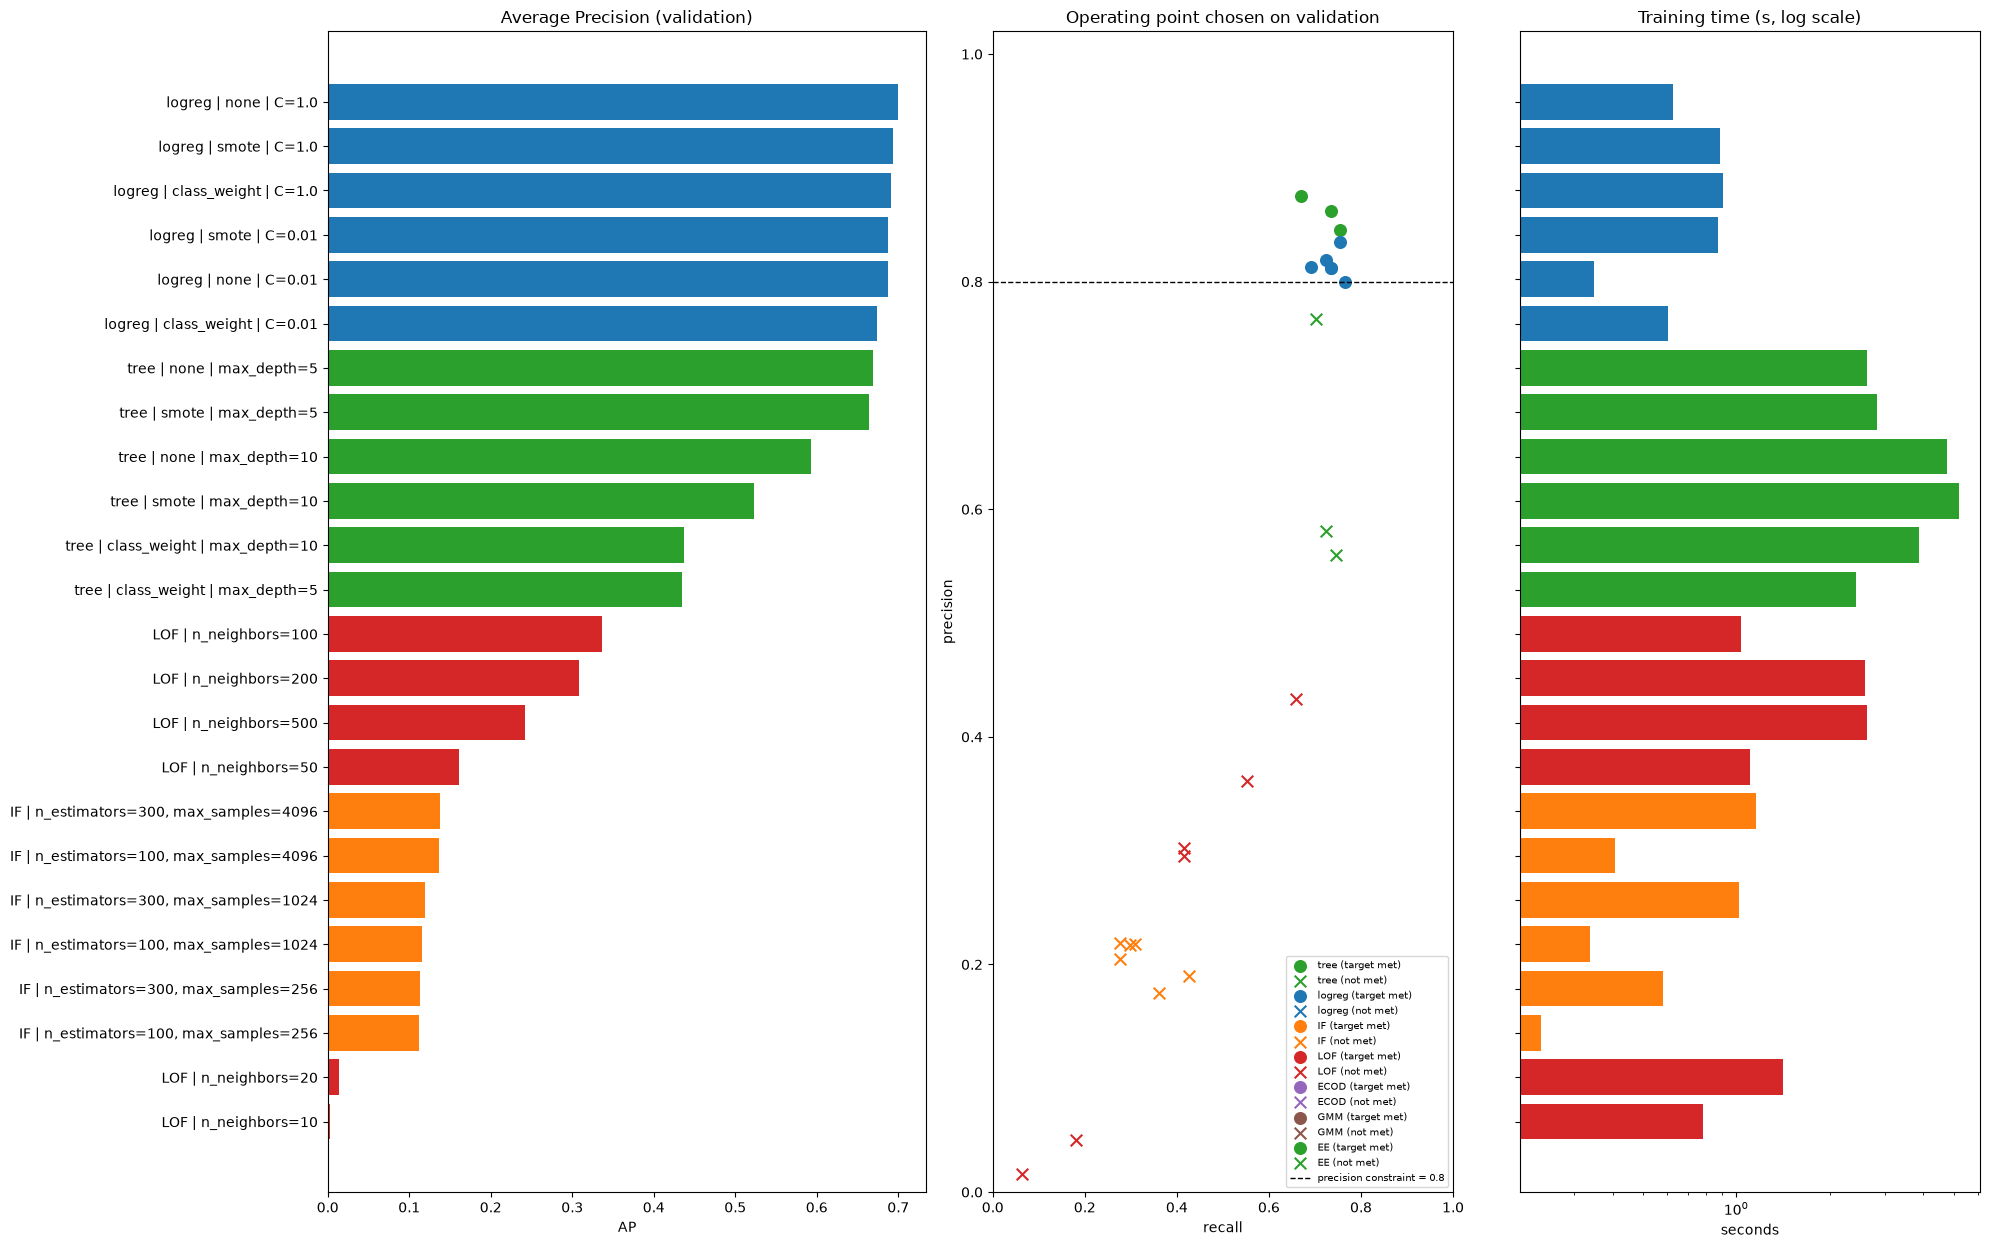

In [6]:
utils.plot_config_overview(pd.concat([res_sup, res_unsup])); plt.show()

Decision tree          -> tree | smote | max_depth=5
Logistic regression    -> logreg | class_weight | C=1.0
Isolation Forest       -> IF | n_estimators=100, max_samples=4096
LOF                    -> LOF | n_neighbors=100


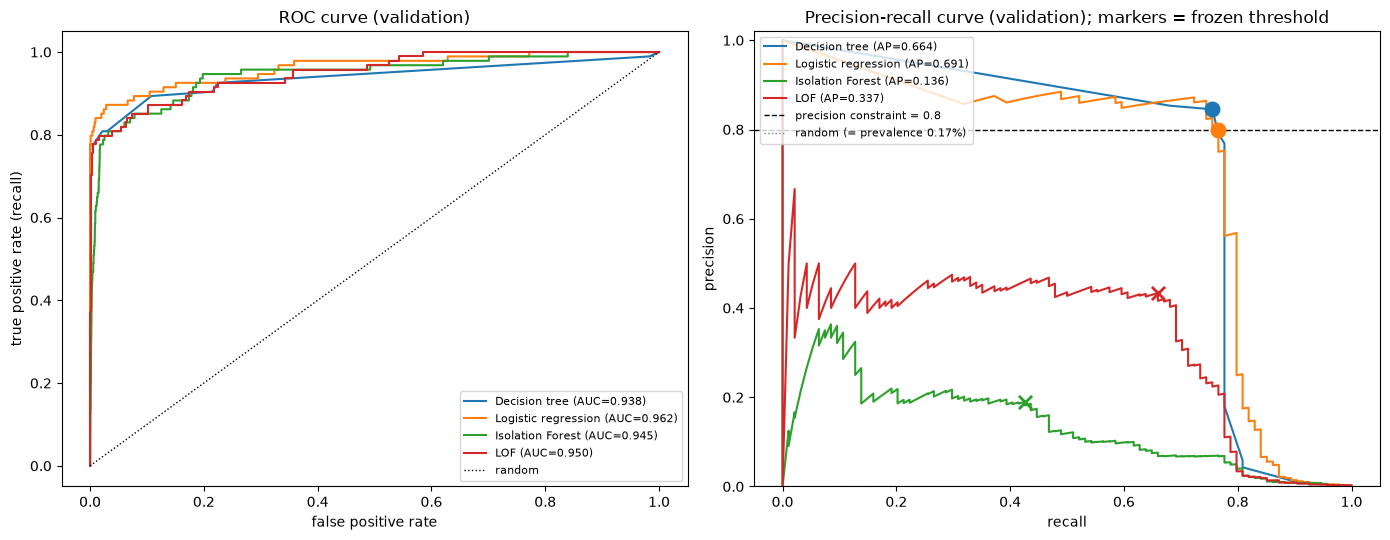

In [7]:
best_cfg, pool, scores_best, rows_val = utils.collect_best_methods(best_sup, best_unsup, sup, unsup)
utils.plot_pr_roc(scores_best, cc['yva'], MIN_PRECISION, rows_val); plt.show()

**Why ROC-AUC is misleading here.** All four methods look similar on the ROC curve (AUC 0.94 to 0.96), because the false positive rate is diluted by 56,651 normal transactions. The **precision-recall curve** shows the difference: supervised models keep 80-90 % precision up to ≈ 75 % recall, while LOF plateaus around 40 % and Isolation Forest around 20 %. This is why **Average Precision (AP)** is the main metric.

## 5. Choosing the decision threshold
Default thresholds (0.5 for classifiers, `predict` for detectors) are compared with the threshold chosen on validation. The best method is then selected and **frozen before looking at the test set**.

,default threshold,alerts (default),precision (default),recall (default),F1 (default),retained threshold,alerts (retained),precision (retained),recall (retained),F1 (retained),target met
Decision tree,0.5,95,0.768421,0.776596,0.772487,0.989201,84,0.845238,0.755319,0.797753,True
Logistic regression,0.5,1482,0.054656,0.861702,0.102792,0.999994,90,0.8,0.765957,0.782609,True
Isolation Forest,0.5,624,0.092949,0.617021,0.16156,0.57846,211,0.189573,0.425532,0.262295,False
LOF,1.5,2844,0.026723,0.808511,0.051736,2.811944,143,0.433566,0.659574,0.523207,False


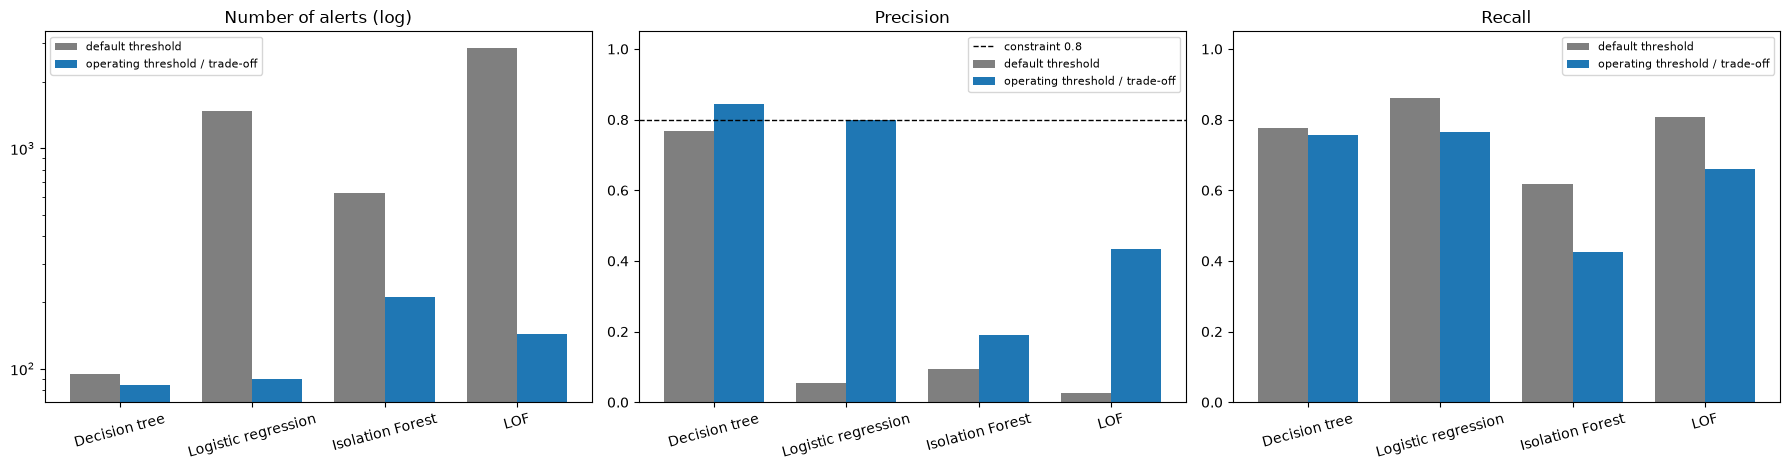

Method selected on validation: Logistic regression  (logreg | class_weight | C=1.0)
  frozen threshold = 0.999994 | validation: precision 0.800, recall 0.766, 90 alerts, target met = True


,config,threshold
Decision tree,tree | smote | max_depth=5,0.989201
Logistic regression,logreg | class_weight | C=1.0,0.999994
Isolation Forest,"IF | n_estimators=100, max_samples=4096",0.57846
LOF,LOF | n_neighbors=100,2.811944


In [8]:
utils.report_default_vs_operational(rows_val); plt.show()
SELECTED, FROZEN = utils.select_and_freeze(rows_val, best_cfg)

**Result.** At the default 0.5 threshold, the weighted logistic regression raises **1,482 alerts** with 5.5 % precision, which is unusable. The tuned threshold brings this down to **90 alerts** at 80 % precision. **The threshold matters as much as the model.**

## 6. Final evaluation on the test set (used once)
Models and thresholds are frozen; nothing is refitted. ★ = method selected on validation.

In [9]:
test_res, final = utils.evaluate_frozen_on_test(pool, FROZEN, SELECTED, rows_val, cc, prep_scaled, MIN_PRECISION)

,preprocessing,imbalance treatment / tuning,AP,AUC-ROC,frozen threshold,precision,recall,F1,bal. acc.,alerts,false alarms (FP),missed frauds (FN),fit time (s),test scoring time (s),constraint ≥ 0.8 met on test
method,,,,,,,,,,,,,,,
Decision tree,log1p(Amount)+StandardScaler (before SMOTE),"SMOTE (ratio 0.1), depth 5",0.650,0.895,0.989,0.804,0.779,0.791,0.889,92,18,21,2.842,0.016,True
★ Logistic regression,log1p(Amount)+StandardScaler,"class weighting, C=1",0.726,0.962,1.000,0.882,0.789,0.833,0.895,85,10,20,0.905,0.010,True
Isolation Forest,none,"none (unsupervised), 100 trees, max_samples=4096",0.237,0.955,0.578,0.201,0.442,0.276,0.720,209,167,53,0.408,0.238,False
LOF,log1p(Amount)+StandardScaler,"none (unsupervised), k=100, 30,000-row subsample",0.403,0.956,2.812,0.463,0.663,0.545,0.831,136,73,32,1.038,2.636,False


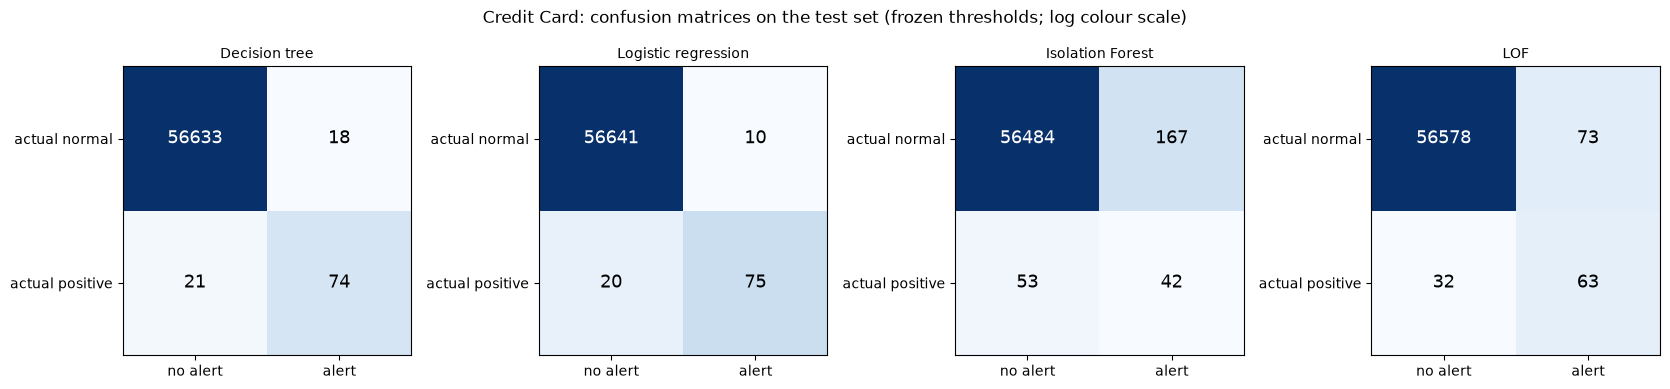

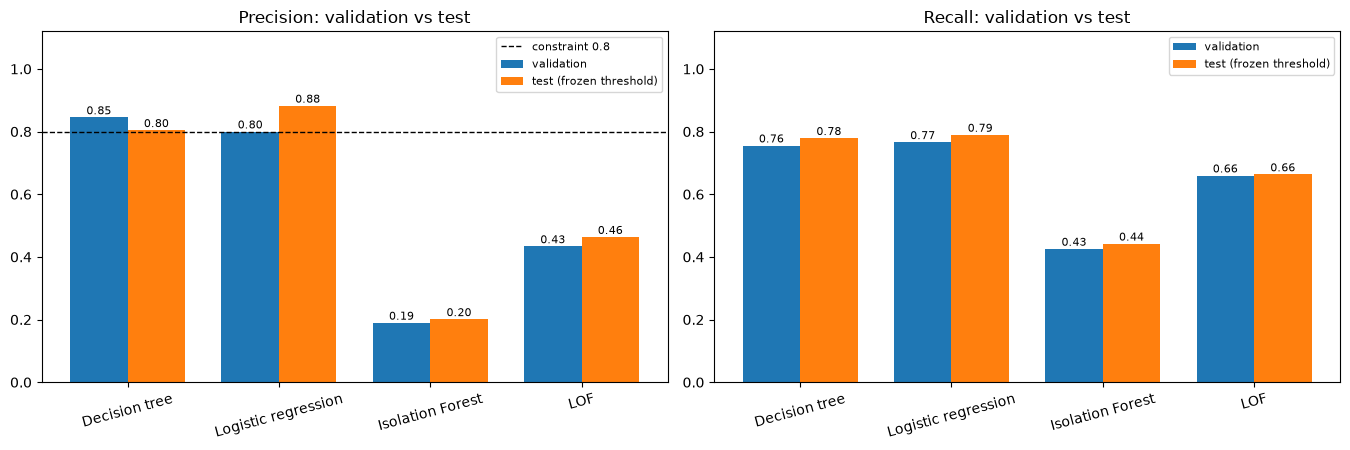

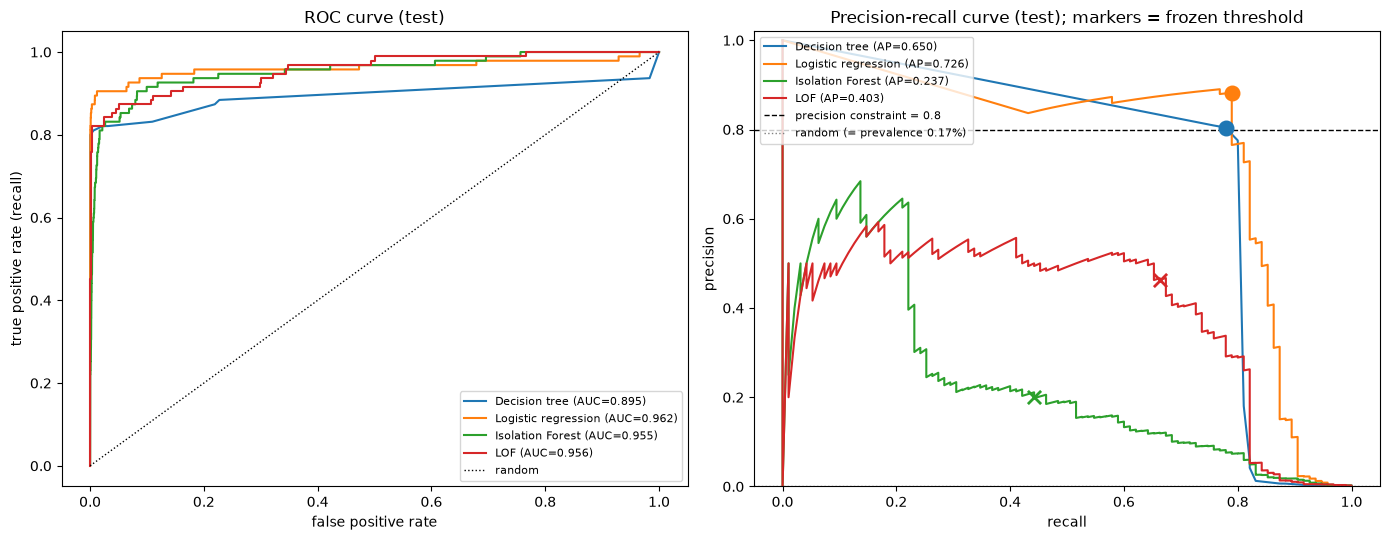

In [10]:
utils.report_test_graphs(test_res, rows_val, cc['yte'], MIN_PRECISION, subject='Credit Card');

In [11]:
utils.report_selected_on_test(test_res, SELECTED, FROZEN, rows_val, MIN_PRECISION)

Test: 56746 observations incl. 95 positives (0.167%) | method: Logistic regression, frozen threshold 0.999994
- alerts to review: 85 (0.150% of observations) incl. 75 true frauds and 10 false alarms
- detected: 75 / 95; missed frauds: 20
- precision 0.882 (95 % Wilson CI: 0.797 - 0.935); recall 0.789 (95 % CI: 0.697 - 0.859)
- precision constraint >= 0.8 met on test: True | val -> test: precision 0.800 -> 0.882, recall 0.766 -> 0.789
- on average 1.13 alerts per true fraud


**In practice.** Out of 56,746 transactions, the team reviews **85 alerts: 75 frauds and 10 false alarms**. **20 frauds out of 95 are missed.** The 80 % constraint holds on the test set (88 %), but its 95 % confidence interval [0.797, 0.935] goes slightly below 0.8, so the result is not guaranteed.

## 7. Explaining alerts with SHAP
Why does Isolation Forest flag a transaction? SHAP decomposes the score of 6 random test transactions (2 detected frauds, 2 false alarms, 2 missed frauds).

Note: for Isolation Forest, `TreeExplainer` explains the **path length** (long path = normal), so raw SHAP values have the opposite sign to suspiciousness. They are flipped here, and the result is checked with `KernelExplainer`.

,model E[h],base + Σ SHAP,mean E[h] background,anomaly score
detected fraud,11.850,11.850,23.742,0.594
detected fraud,10.938,10.938,23.742,0.619
false alarm,11.873,11.873,23.742,0.594
false alarm,10.631,10.631,23.742,0.627
missed fraud,17.640,17.640,23.742,0.461
missed fraud,23.393,23.393,23.742,0.358


Output explained by TreeExplainer = mean path length E[h(x)]; base + Σ SHAP = E[h(x)] for the 6 observations: True
Rank correlation (-tree SHAP vs kernel SHAP on the final score): [0.85 0.84 0.84 0.8  0.85 0.78]
Sign agreement on the 5 most influential features: [1. 1. 1. 1. 1. 1.]
Missing categories filled with other cases: none


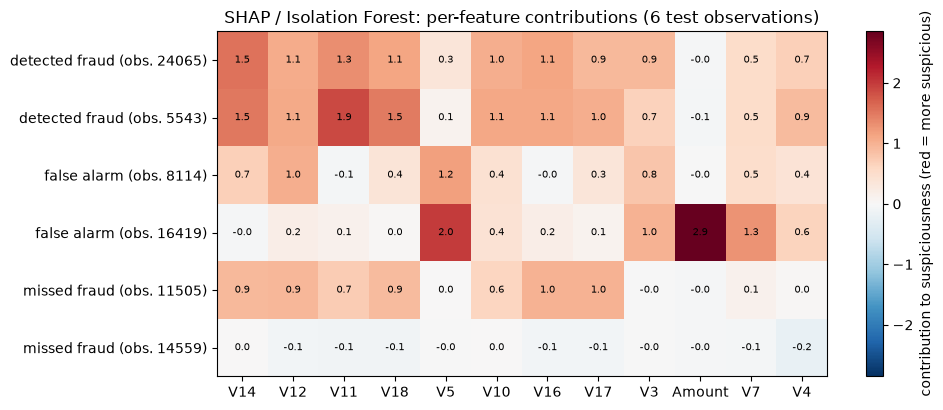

In [12]:
if_model = pool[FROZEN['Isolation Forest']['config']]['model']
shap_res = utils.shap_isolation_forest(if_model, cc['Xtr'], cc['Xte'], cc['yte'], FROZEN['Isolation Forest']['threshold'])
utils.report_shap_checks(shap_res);
utils.plot_shap_heatmap(shap_res); plt.show()

**Reading (red = makes the transaction more suspicious).**
- **Detected frauds**: very low `V14` and very high `V11`, the usual pattern of frauds.
- **False alarms**: driven by other features, such as a very large `Amount`. An unsupervised model flags anything extreme, in either direction.
- **Missed frauds**: one has the same pattern, but weaker; the other is completely ordinary and cannot be caught by any outlier detector.

SHAP describes the model, not causes: `V1`..`V28` are anonymised, so only `Amount` has a business meaning.

## Conclusions
- **Labels matter**: supervised models clearly beat unsupervised detectors (AP ≈ 0.7 vs ≤ 0.4) and are the only ones to meet the 80 % precision target.
- **Pick metrics that fit the imbalance**: AP and precision-recall curves, not accuracy or ROC-AUC.
- **The threshold is a business decision**, tuned on validation, never on the test set.

**Limitations.** The split is random although the data covers 48 hours, so results are probably optimistic; a time-based split would be needed in production. With ≈ 95 frauds per partition, differences of 1-2 % are not significant.

The [full analysis](anomaly_detection.ipynb) also covers toy 2-D data, EasyEnsemble, ECOD, transfer to predictive maintenance (AI4I 2020) and robustness to contaminated training data.